# PUSL 3205 – Lab Sheet 03: Developing a Tiny Transformer Language Model
**Dataset:** `roneneldan/TinyStories` | **Framework:** PyTorch | **Tokenisation:** character level

The notebook follows the 11 steps of the lab sheet. Run the cells from top to bottom (a GPU runtime, e.g. Colab T4, is recommended).

In [1]:
!pip -q install datasets gradio matplotlib pandas

In [1]:
import json, math, os, random, string, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Record the exact environment versions for reproducibility
import platform
from importlib.metadata import version, PackageNotFoundError

print("Python:", platform.python_version())
for package in ("torch", "gradio", "datasets"):
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")

Using device: cuda
Python: 3.13.16
torch: 2.14.1+cu130
gradio: 6.31.0
datasets: 4.8.5


## Step 1 – Load and explore the dataset

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Total training stories: 2119719

--- Story 1 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for shari

--- Story 2 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Beep liked how the leaves fall and w

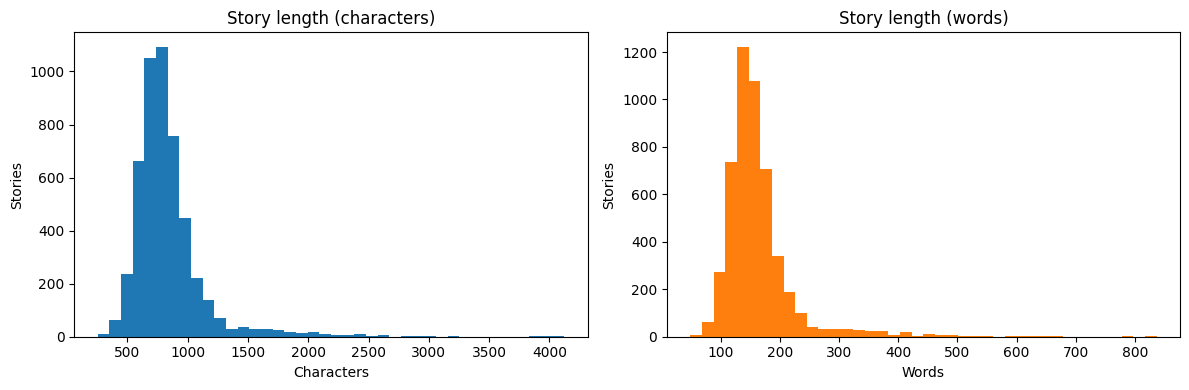

In [3]:
dataset = load_dataset("roneneldan/TinyStories", split="train")
print("Total training stories:", len(dataset))

# Show a few stories
for i in range(3):
    print(f"\n--- Story {i + 1} ---")
    print(dataset[i]["text"][:600])

# Length and structure statistics on a sample of 5,000 stories
sample = dataset.select(range(5000))["text"]
char_lengths = [len(t) for t in sample]
word_lengths = [len(t.split()) for t in sample]
para_counts = [t.count("\n\n") + 1 for t in sample]

print("\nCharacters per story  : mean %.0f | min %d | max %d" % (np.mean(char_lengths), min(char_lengths), max(char_lengths)))
print("Words per story       : mean %.0f | min %d | max %d" % (np.mean(word_lengths), min(word_lengths), max(word_lengths)))
print("Paragraphs per story  : mean %.1f" % np.mean(para_counts))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(char_lengths, bins=40)
ax[0].set(title="Story length (characters)", xlabel="Characters", ylabel="Stories")
ax[1].hist(word_lengths, bins=40, color="tab:orange")
ax[1].set(title="Story length (words)", xlabel="Words", ylabel="Stories")
plt.tight_layout()
plt.show()

## Step 2 – Preprocess the text (subset + character tokeniser)

The raw data contains a few encoding artefacts (curly quotes and characters such as `Ã`, `â`, `€`). They are normalised or removed so the vocabulary only holds useful characters, which makes the task easier for a tiny model.

In [ ]:
NUM_STORIES = 20000          # small subset so training stays manageable
TRAIN_FRACTION = 0.9

# Characters we keep: printable ASCII + newline
ALLOWED = set(string.printable) - set("\t\r\x0b\x0c")
REPLACEMENTS = {"\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"',
                "\u2013": "-", "\u2014": "-", "\u2026": "..."}

def clean_text(text):
    for bad, good in REPLACEMENTS.items():
        text = text.replace(bad, good)
    return "".join(ch for ch in text if ch in ALLOWED).strip()

subset = dataset.shuffle(seed=SEED).select(range(NUM_STORIES))
stories = [clean_text(t) for t in subset["text"]]
stories = [s for s in stories if len(s) > 50]

split_index = int(TRAIN_FRACTION * len(stories))
train_stories, val_stories = stories[:split_index], stories[split_index:]
print("Training stories  :", len(train_stories))
print("Validation stories:", len(val_stories))

# Vocabulary is built from the training text only
train_text = "\n".join(train_stories)
val_text = "\n".join(val_stories)

chars = sorted(set(train_text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(text, strict=False):
    if strict:
        unknown = sorted(set(ch for ch in text if ch not in stoi))
        if unknown:
            raise ValueError(f"Unsupported characters in prompt: {unknown}")
    return [stoi[ch] for ch in text if ch in stoi]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

print("Vocabulary size:", vocab_size)
print("Characters:", repr("".join(chars)))
print("Round trip:", decode(encode("Once upon a time")), "<-", encode("Once upon a time"))

Training stories  : 17999
Validation stories: 2000
Vocabulary size: 82
Characters: '\n !"$\'()*+,-./0123456789:;>?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]abcdefghijklmnopqrstuvwxyz'
Round trip: Once upon a time <- [42, 69, 58, 60, 1, 76, 71, 70, 69, 1, 56, 1, 75, 64, 68, 60]


## Step 3 – Prepare training data

The model sees `block_size` characters and must predict the *next* character at every position, so the target sequence is the input shifted one position to the right. Dataset text skips any character outside the training vocabulary (the count is printed); user prompts are checked strictly.

In [ ]:
train_ids = torch.tensor(encode(train_text), dtype=torch.long)
val_ids = torch.tensor(encode(val_text), dtype=torch.long)
print("Training tokens  :", f"{len(train_ids):,}")
print("Validation tokens:", f"{len(val_ids):,}")
print("Characters skipped (not in training vocabulary):",
      len(train_text) - len(train_ids), "train |", len(val_text) - len(val_ids), "val")

BLOCK_SIZE = 128    # context length
BATCH_SIZE = 64

def get_batch(split, batch_size=BATCH_SIZE, block_size=BLOCK_SIZE):
    data = train_ids if split == "train" else val_ids
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in ix])
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train", batch_size=1, block_size=40)
print("Input :", repr(decode(xb[0].tolist())))
print("Target:", repr(decode(yb[0].tolist())))
print("Shapes:", xb.shape, yb.shape)

Training tokens  : 16,042,285
Validation tokens: 1,758,422
Characters skipped (not in training vocabulary): 0 train | 0 val
Input : ' the grass and watched the chickens cook'
Target: 'the grass and watched the chickens cook.'
Shapes: torch.Size([1, 40]) torch.Size([1, 40])


## Step 4 – Build the Transformer

Components: token embeddings, positional embeddings, **masked multi-head self-attention**, feed-forward layers, **residual connections** and **layer normalisation** (pre-norm), written explicitly in PyTorch.

In [ ]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, dropout, block_size):
        super().__init__()
        assert n_embd % n_head == 0, "n_embd must be divisible by n_head"
        self.n_head = n_head
        self.head_size = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
       
        mask = torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size)
        self.register_buffer("mask", mask)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.n_head, self.head_size).transpose(1, 2)   # (B, heads, T, head_size)
        k = k.view(B, T, self.n_head, self.head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_size).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_size)  # scaled dot-product
        scores = scores.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        weights = self.attn_dropout(F.softmax(scores, dim=-1))

        out = (weights @ v).transpose(1, 2).contiguous().view(B, T, C)  # join the heads
        return self.resid_dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.fc1 = nn.Linear(n_embd, 4 * n_embd)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(4 * n_embd, n_embd)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.fc2(self.act(self.fc1(x))))


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, dropout, block_size):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, dropout, block_size)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connection around attention
        x = x + self.ffn(self.ln2(x))    # residual connection around feed-forward
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, block_size=128, n_embd=128, n_head=4, n_layer=4, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            [TransformerBlock(n_embd, n_head, dropout, block_size) for _ in range(n_layer)]
        )
        self.ln_final = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding.weight   # weight tying

        # Small initial weights -> initial loss close to ln(vocab_size)
        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("proj.weight") or name.endswith("fc2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        positions = torch.arange(T, device=idx.device)
        x = self.drop(self.token_embedding(idx) + self.position_embedding(positions))
        for block in self.blocks:
            x = block(x)
        logits = self.lm_head(self.ln_final(x))

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=300, temperature=0.8, top_k=20):
        was_training = self.training
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k is not None:
                k = min(top_k, logits.size(-1))
                values, _ = torch.topk(logits, k)
                logits = logits.masked_fill(logits < values[:, [-1]], float("-inf"))
            probs = F.softmax(logits, dim=-1)
            idx = torch.cat((idx, torch.multinomial(probs, num_samples=1)), dim=1)
        if was_training:
            self.train()
        return idx

print("Model classes defined.")

Model classes defined.


## Step 5 – Initialise the model, loss function and optimiser

* **Loss:** cross-entropy between the predicted distribution and the true next character.
* **Optimiser:** AdamW (weight decay applied to weight matrices only).
* **Sanity check:** an untrained model should have a loss close to `ln(vocab_size)`.

In [7]:
def make_model(**overrides):
    cfg = dict(vocab_size=vocab_size, block_size=BLOCK_SIZE,
               n_embd=256, n_head=4, n_layer=4, dropout=0.1)
    cfg.update(overrides)
    return TinyTransformer(**cfg).to(device), cfg

def make_optimizer(model, lr):
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": 0.01},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=lr, betas=(0.9, 0.95)
    )

model, config = make_model()
print("Config:", config)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

with torch.no_grad():
    x, y = get_batch("val")
    _, initial_loss = model(x, y)
print(f"Initial loss: {initial_loss.item():.3f}   (ln(vocab_size) = {math.log(vocab_size):.3f})")

Config: {'vocab_size': 82, 'block_size': 128, 'n_embd': 256, 'n_head': 4, 'n_layer': 4, 'dropout': 0.1}
Parameters: 3,213,312
Initial loss: 4.432   (ln(vocab_size) = 4.407)


## Steps 6 & 7 – Train the model and monitor loss

Each **epoch** here is `STEPS_PER_EPOCH` mini-batch updates. After every epoch we record the average training loss and the validation loss. A learning-rate schedule (linear warm-up, then cosine decay) and gradient clipping are used for stable training, and the best checkpoint (lowest validation loss) is kept.

In [8]:
@torch.no_grad()
def evaluate(model, split, num_batches=50):
    was_training = model.training
    model.eval()
    losses = []
    for _ in range(num_batches):
        x, y = get_batch(split)
        _, loss = model(x, y)
        losses.append(loss.item())
    if was_training:
        model.train()
    return float(np.mean(losses))


def lr_at(step, total_steps, base_lr, warmup=200, min_ratio=0.1):
    if step < warmup:
        return base_lr * (step + 1) / warmup
    progress = (step - warmup) / max(1, total_steps - warmup)
    return base_lr * (min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * progress)))


def train_model(model, epochs, steps_per_epoch, base_lr=1e-3, eval_batches=50, verbose=True):
    optimizer = make_optimizer(model, base_lr)
    total_steps = epochs * steps_per_epoch
    train_hist, val_hist = [], []
    best_val, best_state = float("inf"), None
    step, start = 0, time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for _ in range(steps_per_epoch):
            for group in optimizer.param_groups:
                group["lr"] = lr_at(step, total_steps, base_lr)
            x, y = get_batch("train")
            _, loss = model(x, y)                                    # forward pass + cross-entropy
            optimizer.zero_grad(set_to_none=True)
            loss.backward()                                          # backpropagation
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # avoid exploding gradients
            optimizer.step()                                         # update parameters
            running += loss.item()
            step += 1

        train_loss = running / steps_per_epoch
        val_loss = evaluate(model, "val", eval_batches)
        train_hist.append(train_loss)
        val_hist.append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"Epoch {epoch:2d}/{epochs} | train {train_loss:.4f} | val {val_loss:.4f} | "
                  f"lr {optimizer.param_groups[0]['lr']:.2e} | {time.time() - start:.0f}s")

    model.load_state_dict(best_state)    # restore the best checkpoint
    return train_hist, val_hist, best_val, time.time() - start

In [ ]:
EPOCHS = 50
STEPS_PER_EPOCH = 200       
LEARNING_RATE = 1e-3

train_hist, val_hist, best_val, seconds = train_model(
    model, EPOCHS, STEPS_PER_EPOCH, base_lr=LEARNING_RATE
)
print(f"\nTraining finished in {seconds/60:.1f} min. Best validation loss: {best_val:.4f}")

Epoch  1/50 | train 2.4902 | val 1.9900 | lr 1.00e-03 | 16s
Epoch  2/50 | train 1.7208 | val 1.4206 | lr 9.99e-04 | 31s
Epoch  3/50 | train 1.3854 | val 1.2140 | lr 9.96e-04 | 48s
Epoch  4/50 | train 1.2397 | val 1.1264 | lr 9.92e-04 | 66s
Epoch  5/50 | train 1.1558 | val 1.0660 | lr 9.85e-04 | 84s
Epoch  6/50 | train 1.1021 | val 1.0208 | lr 9.77e-04 | 100s
Epoch  7/50 | train 1.0614 | val 0.9818 | lr 9.67e-04 | 117s
Epoch  8/50 | train 1.0349 | val 0.9660 | lr 9.55e-04 | 134s
Epoch  9/50 | train 1.0075 | val 0.9432 | lr 9.42e-04 | 151s
Epoch 10/50 | train 0.9915 | val 0.9291 | lr 9.27e-04 | 169s
Epoch 11/50 | train 0.9739 | val 0.9140 | lr 9.11e-04 | 186s
Epoch 12/50 | train 0.9589 | val 0.9056 | lr 8.93e-04 | 203s
Epoch 13/50 | train 0.9423 | val 0.8984 | lr 8.73e-04 | 220s
Epoch 14/50 | train 0.9361 | val 0.8903 | lr 8.53e-04 | 237s
Epoch 15/50 | train 0.9263 | val 0.8722 | lr 8.31e-04 | 254s
Epoch 16/50 | train 0.9171 | val 0.8683 | lr 8.08e-04 | 271s
Epoch 17/50 | train 0.9080 | 

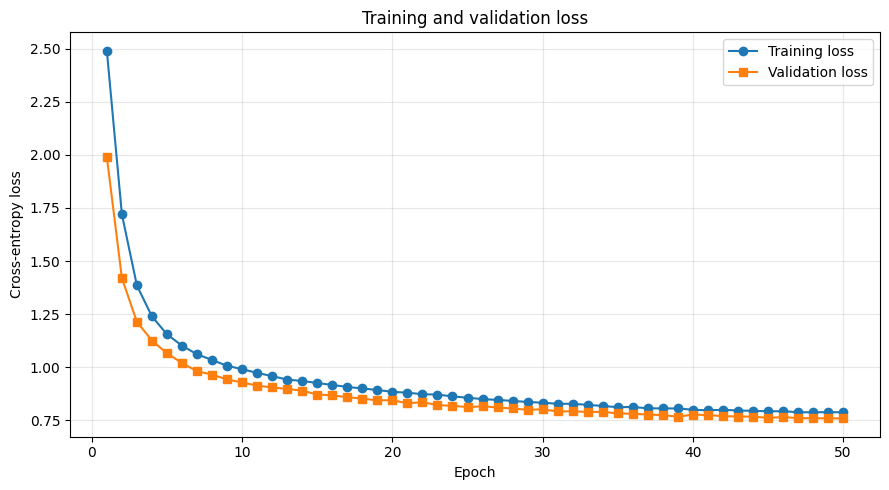

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), train_hist, marker="o", label="Training loss")
plt.plot(range(1, EPOCHS + 1), val_hist, marker="s", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and validation loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Step 8 – Evaluate: validation loss and perplexity

Perplexity = exp(cross-entropy loss). Because this model works on **characters**, the value means "on average the model is as uncertain as choosing between *PPL* equally likely next characters". It is **not comparable with word-level perplexity**.

In [11]:
final_val_loss = evaluate(model, "val", num_batches=200)
final_train_loss = evaluate(model, "train", num_batches=200)

print(f"Training   loss: {final_train_loss:.4f} | perplexity: {math.exp(final_train_loss):.3f}")
print(f"Validation loss: {final_val_loss:.4f} | perplexity: {math.exp(final_val_loss):.3f}")
print(f"Bits per character (validation): {final_val_loss / math.log(2):.3f}")

Training   loss: 0.7426 | perplexity: 2.101
Validation loss: 0.7600 | perplexity: 2.138
Bits per character (validation): 1.097


## Step 9 – Generate stories

In [12]:
def generate_text(model, prompt, max_new_chars=400, temperature=0.8, top_k=20):
    ids = encode(prompt, strict=True) or [stoi.get(" ", 0)]   # raises ValueError on unsupported characters
    context = torch.tensor([ids], dtype=torch.long, device=device)
    out = model.generate(context, max_new_tokens=max_new_chars, temperature=temperature, top_k=top_k)
    return decode(out[0].tolist())

for temp in (0.5, 0.8, 1.1):
    print(f"\n===== temperature = {temp} =====")
    print(generate_text(model, "Once upon a time", max_new_chars=400, temperature=temp))


===== temperature = 0.5 =====
Once upon a time, there was a little girl named Lily. She loved to play outside in the park every day. One day, she found a big box of paper and was playing a game. She was so excited to have a big box of socks that she wanted to keep the box. 

The boy was so excited that he said to her mommy, "It's okay, Lily. I will come back to my house." 

Lily was so happy and grateful for her and she said, "I'm sorry I wan

===== temperature = 0.8 =====
Once upon a time, there was a little girl named Lily. She loved to play outside with her friends. One day, she went to the park with her mommy and daddy. As she waited, she saw a big park with a big brown bike. She ran over to the fence and she carefully began to stop. Suddenly, a big fish came outside. It was pink and water and caught her mouths. It was a big strange bear! Lily was so happy too, she said goodbye

===== temperature = 1.1 =====
Once upon a time, there was a little boy named Timmy. Timmy loved to play

## Step 10 – Experiment with model settings

The same training function is re-used for several configurations (smaller model width and fewer updates so the whole table runs in a few minutes on a GPU). We vary **the number of layers**, **the number of attention heads** and **the number of epochs**.

In [ ]:
EXP_EMBD = 128
EXP_STEPS_PER_EPOCH = 100

experiments = [
    # name, layers, heads, epochs
    ("1 layer, 4 heads, 10 ep",  1, 4, 10),
    ("2 layers, 4 heads, 10 ep", 2, 4, 10),
    ("4 layers, 4 heads, 10 ep", 4, 4, 10),
    ("6 layers, 4 heads, 10 ep", 6, 4, 10),
    ("4 layers, 1 head, 10 ep",  4, 1, 10),
    ("4 layers, 8 heads, 10 ep", 4, 8, 10),
    ("4 layers, 4 heads, 3 ep",  4, 4, 3),
    ("4 layers, 4 heads, 20 ep", 4, 4, 20),
]

rows, curves, samples = [], {}, {}
for name, n_layer, n_head, epochs in experiments:
    torch.manual_seed(SEED)
    m, cfg = make_model(n_embd=EXP_EMBD, n_layer=n_layer, n_head=n_head)
    n_params = sum(p.numel() for p in m.parameters())
    tr, va, best, secs = train_model(m, epochs, EXP_STEPS_PER_EPOCH, base_lr=LEARNING_RATE,
                                     eval_batches=30, verbose=False)
    curves[name] = (tr, va)
    samples[name] = generate_text(m, "Once upon a time", max_new_chars=200, temperature=0.8)
    best_epoch = va.index(min(va))      # the restored checkpoint comes from this epoch
    rows.append({"Configuration": name, "Layers": n_layer, "Heads": n_head, "Epochs": epochs,
                 "Iterations": epochs * EXP_STEPS_PER_EPOCH, "Params": f"{n_params:,}",
                 "Training loss": round(tr[best_epoch], 4), "Validation loss": round(best, 4),
                 "Perplexity": round(math.exp(best), 3), "Time (s)": round(secs)})
    print(f"done: {name:28s} val loss {best:.4f}")
    del m

results = pd.DataFrame(rows)
display(results)

# Save the comparison table and the generated samples for the report
os.makedirs("tiny_transformer", exist_ok=True)
results.to_json("tiny_transformer/experiment_results.json", orient="records", indent=4)
with open("tiny_transformer/experiment_samples.json", "w", encoding="utf-8") as f:
    json.dump(samples, f, ensure_ascii=False, indent=4)
print("Experiment results saved to tiny_transformer/experiment_results.json")

done: 1 layer, 4 heads, 10 ep      val loss 1.6074
done: 2 layers, 4 heads, 10 ep     val loss 1.5002
done: 4 layers, 4 heads, 10 ep     val loss 1.4069
done: 6 layers, 4 heads, 10 ep     val loss 1.3403
done: 4 layers, 1 head, 10 ep      val loss 1.4251
done: 4 layers, 8 heads, 10 ep     val loss 1.3976
done: 4 layers, 4 heads, 3 ep      val loss 2.0823
done: 4 layers, 4 heads, 20 ep     val loss 1.1522


,Configuration,Layers,Heads,Epochs,Iterations,Params,Training loss,Validation loss,Perplexity,Time (s)
0,"1 layer, 4 heads, 10 ep",1,4,10,1000,"225,408",1.8048,1.6074,4.990,11
1,"2 layers, 4 heads, 10 ep",2,4,10,1000,"423,680",1.6832,1.5002,4.482,20
2,"4 layers, 4 heads, 10 ep",4,4,10,1000,"820,224",1.5365,1.4069,4.083,38
3,"6 layers, 4 heads, 10 ep",6,4,10,1000,"1,216,768",1.4473,1.3403,3.820,55
4,"4 layers, 1 head, 10 ep",4,1,10,1000,"820,224",1.5766,1.4251,4.158,29
5,"4 layers, 8 heads, 10 ep",4,8,10,1000,"820,224",1.5153,1.3976,4.045,48
6,"4 layers, 4 heads, 3 ep",4,4,3,300,"820,224",2.2042,2.0823,8.023,11
7,"4 layers, 4 heads, 20 ep",4,4,20,2000,"820,224",1.2498,1.1522,3.165,75


Experiment results saved to tiny_transformer/experiment_results.json


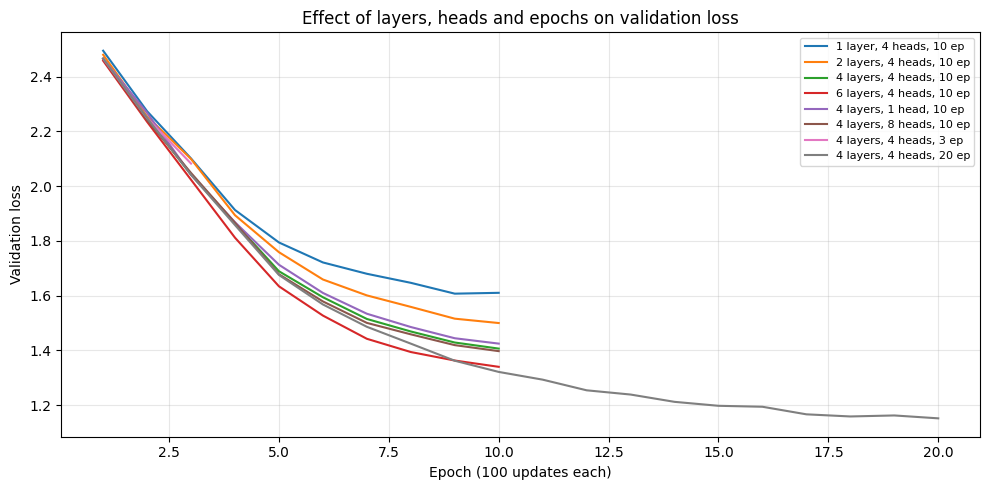


--- 1 layer, 4 heads, 10 ep ---
Once upon a time, the tre and to the becar ack. At the dop roch fooly ausese a tut frome it and said to so round he ose was love trad marted the said the fiend was nots.


It ill fas ight ide trearnd watenting an and

--- 2 layers, 4 heads, 10 ep ---
Once upon a time, there was such to chet was staze and things ent to her to abok. She feeel huged a the bard came chom. And Max wanted the goig of his at the sace it son the spicke in she mome.


They saw as big bing

--- 4 layers, 4 heads, 10 ep ---
Once upon a time, there was vite. He puter all it her. The could to the bark of explay. Wen was they their mom. They was a in little friend her stil. One day, they bird felt was a light thing. The farde whing that th

--- 6 layers, 4 heads, 10 ep ---
Once upon a time, there was a bunny and stays, Lily and she find forget car, "I in, I let to take!" Mum said, "What don't work to the got the was and the smiled. It know a play with is faleful in she are his wort l

In [14]:
plt.figure(figsize=(10, 5))
for name, (tr, va) in curves.items():
    plt.plot(range(1, len(va) + 1), va, label=name)
plt.xlabel("Epoch (100 updates each)")
plt.ylabel("Validation loss")
plt.title("Effect of layers, heads and epochs on validation loss")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

for name, text in samples.items():
    print(f"\n--- {name} ---\n{text}")


### Observations

The results show that increasing the number of Transformer layers reduced the validation loss. It decreased from 1.6074 with 1 layer to 1.5002 with 2 layers, 1.4069 with 4 layers, and 1.3403 with 6 layers. However, the improvement became smaller as more layers were added: the reductions were approximately 0.107, 0.093, and 0.067, respectively, suggesting diminishing returns.

The attention-head experiments produced relatively close validation losses: 1.4251 with 1 head, 1.4069 with 4 heads, and 1.3976 with 8 heads. Since each configuration was run only once using one random seed, these small differences should not be treated as conclusive evidence that one head configuration is better than another. All three configurations also had the same parameter count of 820,224 because the embedding dimension remained fixed at 128.

Increasing the number of epochs from 3 to 10 and then to 20 reduced validation loss from 2.0823 to 1.4069 and 1.1522. In this experiment, increasing the epochs also increased the total number of training updates from 300 to 1,000 and 2,000, so the improvement reflects longer training rather than epochs alone.

The main model is not directly comparable with these experiments because it uses an embedding dimension of 256 and 10,000 training updates, whereas the experiments use an embedding dimension of 128 and between 300 and 2,000 updates. Although the experimental validation losses improved, the generated stories still contained spelling mistakes and grammatically incorrect sentences. Overall, the experiments demonstrate that model depth and training duration can improve next-character prediction, but larger models and longer training also require more computational resources.


## Step 11 – Save the trained model

The weights, configuration, vocabulary and loss history are saved so text can be generated later without retraining.

In [15]:
OUT = Path("tiny_transformer")
OUT.mkdir(exist_ok=True)

torch.save({"model_state_dict": model.state_dict(), "config": config}, OUT / "model.pth")
with open(OUT / "vocab.json", "w", encoding="utf-8") as f:
    json.dump({"stoi": stoi, "itos": {str(k): v for k, v in itos.items()}}, f, ensure_ascii=False)
with open(OUT / "history.json", "w") as f:
    json.dump({"train": train_hist, "val": val_hist, "val_loss": final_val_loss,
               "perplexity": math.exp(final_val_loss)}, f)
print("Saved to:", OUT.resolve(), os.listdir(OUT))

Saved to: /content/tiny_transformer ['experiment_results.json', 'history.json', 'experiment_samples.json', 'vocab.json', 'model.pth']


In [16]:
# Reload everything from disk to prove the saved files are enough for generation
checkpoint = torch.load(OUT / "model.pth", map_location=device, weights_only=True)
loaded_model = TinyTransformer(**checkpoint["config"]).to(device)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

with open(OUT / "vocab.json", "r", encoding="utf-8") as f:
    vocab_data = json.load(f)
stoi = vocab_data["stoi"]
itos = {int(k): v for k, v in vocab_data["itos"].items()}

print(generate_text(loaded_model, "One day, a little girl", max_new_chars=250))

One day, a little girl named Emma was so excited to bake a new friend. She had a big soft bucket that she couldn't stop playing. She was so happy and hugged her mommy and so they went back home. Lucy was happy that she could go home.
Once upon a time, there was a little g


## Chat window with Gradio

In [17]:
import gradio as gr

def chat_fn(message, history, max_chars, temperature):
    if not message or not message.strip():
        return "Please type a story opening, e.g. 'Once upon a time'."
    try:
        full_text = generate_text(loaded_model, message, int(max_chars), float(temperature))
    except ValueError as err:
        return f"Sorry - {err}. Please use only letters, digits and common punctuation."
    return full_text[len(message):] if full_text.startswith(message) else full_text   # continuation only

demo = gr.ChatInterface(
    fn=chat_fn,
    additional_inputs=[
        gr.Slider(50, 600, value=250, step=50, label="Maximum new characters"),
        gr.Slider(0.3, 1.5, value=0.8, step=0.1, label="Temperature"),
    ],
    title="Tiny Transformer Story Generator",
    description="A character-level Transformer trained from scratch on TinyStories. "
                "Type the beginning of a story and the model will continue it.",
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2c949322619a7b3eea.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Discussion – mechanisms used to improve performance

| Mechanism | Where it is used | Why it helps |
|---|---|---|
| **Causal (masked) self-attention** | `CausalSelfAttention` | Lets every position use earlier context while preventing it from "seeing" the answer, which is required for next-token prediction. |
| **Multi-head attention** | `n_head` | Different heads can focus on different relationships (e.g. recent letters, word starts, punctuation). |
| **Positional embeddings** | `position_embedding` | Attention itself has no notion of order; positions tell the model where each character is. |
| **Residual connections** | `x = x + ...` in each block | Keep an identity path for gradients, so deeper models train stably. |
| **Layer normalisation (pre-norm)** | `ln1`, `ln2`, `ln_final` | Keeps activations at a stable scale and speeds up convergence. |
| **GELU feed-forward (4x expansion)** | `FeedForward` | Adds non-linear capacity to transform each position's representation. |
| **Dropout** | attention, residual, embeddings | Regularisation that reduces over-fitting. |
| **Weight tying** | `lm_head.weight = token_embedding.weight` | Fewer parameters; input and output share one character representation. |
| **Careful weight initialisation** | `_init_weights` | Start with loss ≈ ln(vocab) instead of a huge value, so early training is not wasted. |
| **AdamW + weight decay** | `make_optimizer` | Adaptive learning rates with proper decoupled regularisation. |
| **LR warm-up + cosine decay** | `lr_at` | Avoids unstable early updates, then fine-tunes with a small learning rate. |
| **Gradient clipping** | `clip_grad_norm_` | Prevents occasional exploding gradients. |
| **Best-checkpoint selection** | `train_model` | Keeps the model with the lowest validation loss. |
| **Temperature & top-k sampling** | `generate` | Controls the trade-off between creativity and coherence in generated text. |
